<a href="https://colab.research.google.com/github/sabbirpuspo/smart-grid-stability-ml-benchmark/blob/main/smart_grid_stability_ml_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# Project: Smart Grid Stability Prediction
# Purpose: Machine Learning Benchmark
# Dataset: Electrical Grid Stability Simulated Data
# Environment: Google Colab
# ============================================================

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nProject environment initialized successfully.")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1

Project environment initialized successfully.


In [2]:
# ============================================================
# Step 1: Mount Google Drive
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully.")

Mounted at /content/drive
Google Drive connected successfully.


In [3]:
# ============================================================
# Step 2: Locate the dataset
# ============================================================

import os

dataset_folder = "/content/drive/MyDrive/Smart Grid Stability Dataset"

print("Files in the dataset folder:")

for filename in os.listdir(dataset_folder):
    print(filename)

Files in the dataset folder:
smart_grid_stability_augmented.csv


In [4]:
# ============================================================
# Step 3: Load the smart-grid dataset
# ============================================================

import pandas as pd

file_path = os.path.join(
    dataset_folder,
    "smart_grid_stability_augmented.csv"
)

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of samples:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of samples: 60000
Number of columns: 14


In [5]:
df.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [6]:
print(df.columns.tolist())

['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4', 'stab', 'stabf']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    60000 non-null  float64
 1   tau2    60000 non-null  float64
 2   tau3    60000 non-null  float64
 3   tau4    60000 non-null  float64
 4   p1      60000 non-null  float64
 5   p2      60000 non-null  float64
 6   p3      60000 non-null  float64
 7   p4      60000 non-null  float64
 8   g1      60000 non-null  float64
 9   g2      60000 non-null  float64
 10  g3      60000 non-null  float64
 11  g4      60000 non-null  float64
 12  stab    60000 non-null  float64
 13  stabf   60000 non-null  object 
dtypes: float64(13), object(1)
memory usage: 6.4+ MB


In [8]:
df["stabf"].value_counts()

,count
stabf,
unstable,38280
stable,21720


In [9]:
print("Class counts:")
print(df["stabf"].value_counts())

print("\nClass percentages:")
print(
    (df["stabf"].value_counts(normalize=True) * 100).round(2)
)


Class counts:
stabf
unstable    38280
stable      21720
Name: count, dtype: int64

Class percentages:
stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64


In [10]:
print("Missing values per column:")
print(df.isnull().sum())


Missing values per column:
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64


In [11]:
print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print(
    "Duplicate percentage:",
    round(df.duplicated().mean() * 100, 2),
    "%"
)

Total rows: 60000
Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [12]:
print(
    pd.crosstab(
        df["stabf"],
        df["stab"] > 0,
        rownames=["Stability label"],
        colnames=["stab > 0"]
    )
)

stab > 0         False  True 
Stability label              
stable           21720      0
unstable             0  38280


stabf
unstable    38280
stable      21720
Name: count, dtype: int64


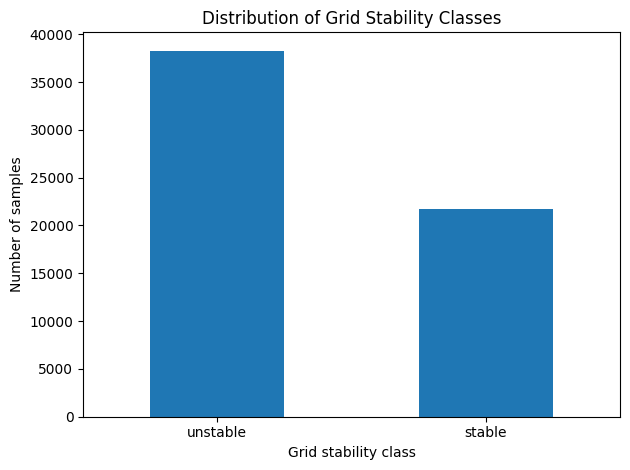

In [13]:
class_counts = df["stabf"].value_counts()

print(class_counts)

class_counts.plot(
    kind="bar",
    xlabel="Grid stability class",
    ylabel="Number of samples",
    title="Distribution of Grid Stability Classes",
    rot=0
)

plt.tight_layout()
plt.show()


In [14]:
print("Column data types:")
print(df.dtypes)

print("\nUnique stability labels:")
print(df["stabf"].unique())

Column data types:
tau1     float64
tau2     float64
tau3     float64
tau4     float64
p1       float64
p2       float64
p3       float64
p4       float64
g1       float64
g2       float64
g3       float64
g4       float64
stab     float64
stabf     object
dtype: object

Unique stability labels:
['unstable' 'stable']


In [15]:
print(df["stab"].describe())

print("\nStability label versus numerical measure:")
print(pd.crosstab(df["stabf"], df["stab"] > 0))


count    60000.000000
mean         0.015731
std          0.036917
min         -0.080760
25%         -0.015557
50%          0.017142
75%          0.044878
max          0.109403
Name: stab, dtype: float64

Stability label versus numerical measure:
stab      False  True 
stabf                 
stable    21720      0
unstable      0  38280


In [16]:
# Define the 12 input features
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p1", "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

# Create input features and target
X = df[feature_columns]
y = df["stabf"]

# Check their shapes
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

# Preview the input features
print("\nFirst five rows of X:")
print(X.head())

print("\nFirst five target labels:")
print(y.head())

Input features shape: (60000, 12)
Target shape: (60000,)

First five rows of X:
       tau1      tau2      tau3      tau4        p1        p2        p3  \
0  2.959060  3.079885  8.381025  9.780754  3.763085 -0.782604 -1.257395   
1  9.304097  4.902524  3.047541  1.369357  5.067812 -1.940058 -1.872742   
2  8.971707  8.848428  3.046479  1.214518  3.405158 -1.207456 -1.277210   
3  0.716415  7.669600  4.486641  2.340563  3.963791 -1.027473 -1.938944   
4  3.134112  7.608772  4.943759  9.857573  3.525811 -1.125531 -1.845975   

         p4        g1        g2        g3        g4  
0 -1.723086  0.650456  0.859578  0.887445  0.958034  
1 -1.255012  0.413441  0.862414  0.562139  0.781760  
2 -0.920492  0.163041  0.766689  0.839444  0.109853  
3 -0.997374  0.446209  0.976744  0.929381  0.362718  
4 -0.554305  0.797110  0.455450  0.656947  0.820923  

First five target labels:
0    unstable
1      stable
2    unstable
3    unstable
4    unstable
Name: stabf, dtype: object


In [17]:
# Calculate descriptive statistics for all input features
feature_summary = X.describe().T

# Display each feature's minimum, maximum, mean, and standard deviation
print(
    feature_summary[
        ["min", "max", "mean", "std"]
    ].round(4)
)

         min     max   mean     std
tau1  0.5008  9.9995  5.250  2.7424
tau2  0.5001  9.9998  5.250  2.7424
tau3  0.5001  9.9998  5.250  2.7424
tau4  0.5001  9.9998  5.250  2.7424
p1    1.5826  5.8644  3.750  0.7521
p2   -1.9999 -0.5000 -1.250  0.4330
p3   -1.9999 -0.5000 -1.250  0.4330
p4   -1.9999 -0.5000 -1.250  0.4330
g1    0.0500  0.9999  0.525  0.2742
g2    0.0500  1.0000  0.525  0.2742
g3    0.0500  1.0000  0.525  0.2742
g4    0.0500  1.0000  0.525  0.2742


In [18]:
# Calculate correlations between the 12 input features
correlation_matrix = X.corr()

# Display the correlation matrix
print(correlation_matrix.round(2))

      tau1  tau2  tau3  tau4    p1    p2    p3    p4    g1    g2    g3    g4
tau1  1.00 -0.00 -0.00 -0.00  0.03 -0.02 -0.02 -0.02  0.01  0.01  0.01  0.01
tau2 -0.00  1.00  0.01  0.01  0.00 -0.00 -0.00 -0.00 -0.01  0.01  0.00  0.00
tau3 -0.00  0.01  1.00  0.01  0.00 -0.00 -0.00 -0.00 -0.01  0.00  0.01  0.00
tau4 -0.00  0.01  0.01  1.00  0.00 -0.00 -0.00 -0.00 -0.01  0.00  0.00  0.01
p1    0.03  0.00  0.00  0.00  1.00 -0.58 -0.58 -0.58  0.00  0.00  0.00  0.00
p2   -0.02 -0.00 -0.00 -0.00 -0.58  1.00  0.00  0.00 -0.00 -0.00  0.00  0.00
p3   -0.02 -0.00 -0.00 -0.00 -0.58  0.00  1.00  0.00 -0.00  0.00 -0.00  0.00
p4   -0.02 -0.00 -0.00 -0.00 -0.58  0.00  0.00  1.00 -0.00  0.00  0.00 -0.00
g1    0.01 -0.01 -0.01 -0.01  0.00 -0.00 -0.00 -0.00  1.00  0.00  0.00  0.00
g2    0.01  0.01  0.00  0.00  0.00 -0.00  0.00  0.00  0.00  1.00 -0.01 -0.01
g3    0.01  0.00  0.01  0.00  0.00  0.00 -0.00  0.00  0.00 -0.01  1.00 -0.01
g4    0.01  0.00  0.00  0.01  0.00  0.00  0.00 -0.00  0.00 -0.01 -0.01  1.00

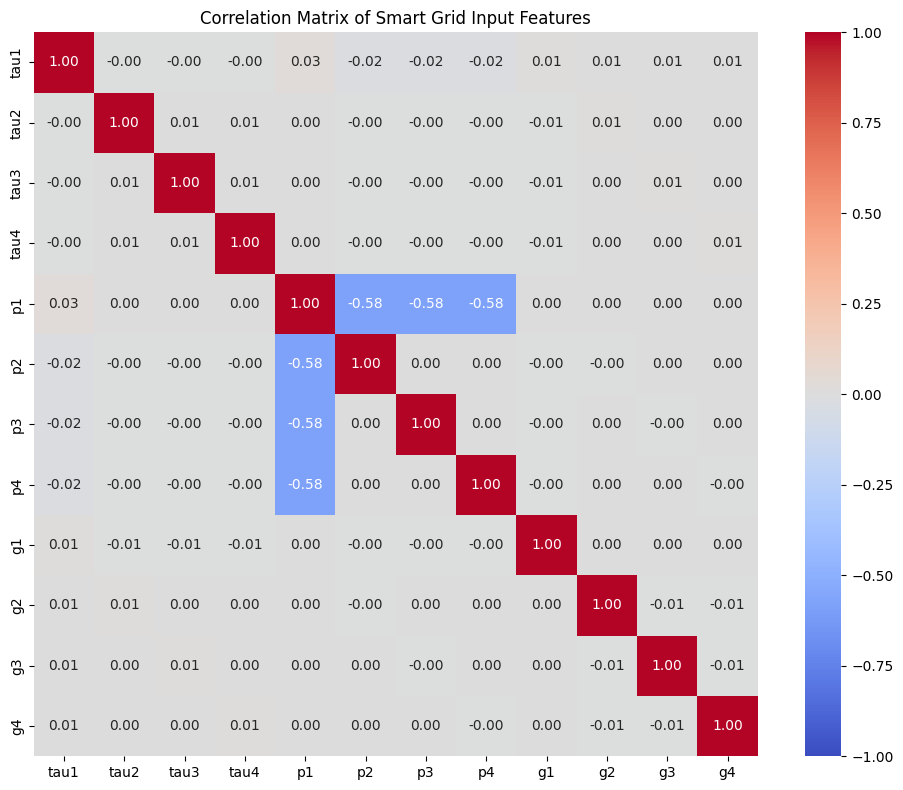

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Matrix of Smart Grid Input Features")
plt.tight_layout()
plt.show()

In [20]:
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p1", "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

X = df[feature_columns]
y = df["stabf"]

In [21]:
print("Feature matrix X shape:", X.shape)
print("Target labels y shape:", y.shape)

print("\nTarget class counts:")
print(y.value_counts())

print("\nTarget class proportions (%):")
print((y.value_counts(normalize=True) * 100).round(2))

Feature matrix X shape: (60000, 12)
Target labels y shape: (60000,)

Target class counts:
stabf
unstable    38280
stable      21720
Name: count, dtype: int64

Target class proportions (%):
stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64


In [22]:
import numpy as np

# Calculate p1 from the three consumer power values
p1_calculated = (
    df["p2"] + df["p3"] + df["p4"]
).abs()

# Measure the difference from the recorded p1
p1_error = (df["p1"] - p1_calculated).abs()

print("Rows in dataset:", len(df))
print(
    "Rows where p1 matches the formula:",
    np.isclose(
        df["p1"],
        p1_calculated,
        atol=1e-8
    ).sum()
)
print("Maximum absolute difference:", p1_error.max())

Rows in dataset: 60000
Rows where p1 matches the formula: 60000
Maximum absolute difference: 6.217248937900877e-15


In [23]:
# Sort the three consumer nodes into a canonical order.
# Each consumer node is represented by its tau, p, and g values.

def canonical_key(row):
    consumer_nodes = [
        (round(row["tau2"], 8),
         round(row["p2"], 8),
         round(row["g2"], 8)),

        (round(row["tau3"], 8),
         round(row["p3"], 8),
         round(row["g3"], 8)),

        (round(row["tau4"], 8),
         round(row["p4"], 8),
         round(row["g4"], 8))
    ]

    # Sorting makes the key independent of consumer-node order.
    consumer_nodes = tuple(sorted(consumer_nodes))

    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        consumer_nodes,
        round(row["stab"], 8),
        row["stabf"]
    )


# Create a canonical key for every row
canonical_keys = df.apply(canonical_key, axis=1)

# Count how many rows correspond to each canonical configuration
group_sizes = canonical_keys.value_counts()

print("Total rows:", len(df))
print("Unique canonical configurations:", len(group_sizes))
print(
    "Groups containing exactly 6 rows:",
    (group_sizes == 6).sum()
)
print(
    "Groups containing a different number of rows:",
    (group_sizes != 6).sum()
)

print("\nDistribution of group sizes:")
print(group_sizes.value_counts().sort_index())

Total rows: 60000
Unique canonical configurations: 10000
Groups containing exactly 6 rows: 10000
Groups containing a different number of rows: 0

Distribution of group sizes:
count
6    10000
Name: count, dtype: int64


In [24]:
# Create a canonical key using system inputs only.
# Do not include stab or stabf in this key.

def canonical_input_key(row):
    consumer_nodes = [
        (round(row["tau2"], 8),
         round(row["p2"], 8),
         round(row["g2"], 8)),

        (round(row["tau3"], 8),
         round(row["p3"], 8),
         round(row["g3"], 8)),

        (round(row["tau4"], 8),
         round(row["p4"], 8),
         round(row["g4"], 8))
    ]

    # Ignore the ordering of the three consumer nodes.
    consumer_nodes = tuple(sorted(consumer_nodes))

    return (
        round(row["tau1"], 8),
        round(row["p1"], 8),
        round(row["g1"], 8),
        consumer_nodes
    )


# Assign the same group ID to equivalent configurations.
canonical_input_keys = df.apply(canonical_input_key, axis=1)
group_ids = pd.factorize(canonical_input_keys)[0]

# Examine each group and its target labels.
group_summary = (
    df.assign(group_id=group_ids)
      .groupby("group_id")
      .agg(
          row_count=("stabf", "size"),
          unique_labels=("stabf", "nunique"),
          unique_stability_values=("stab", "nunique")
      )
)

print("Unique input configurations:", len(group_summary))

print("\nDistribution of group sizes:")
print(group_summary["row_count"].value_counts().sort_index())

print(
    "\nGroups with inconsistent target labels:",
    (group_summary["unique_labels"] > 1).sum()
)

print(
    "Groups with inconsistent stability values:",
    (group_summary["unique_stability_values"] > 1).sum()
)

Unique input configurations: 10000

Distribution of group sizes:
row_count
6    10000
Name: count, dtype: int64

Groups with inconsistent target labels: 0
Groups with inconsistent stability values: 0


In [25]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# Step 1: Select the 11 input features
feature_columns = [
    "tau1", "tau2", "tau3", "tau4",
    "p2", "p3", "p4",
    "g1", "g2", "g3", "g4"
]

X = df[feature_columns]
y = df["stabf"]

print("Input features:", len(feature_columns))
print("X shape:", X.shape)
print("y shape:", y.shape)

Input features: 11
X shape: (60000, 11)
y shape: (60000,)


In [26]:
# Create a table containing one entry per unique configuration
group_table = pd.DataFrame({
    "group_id": group_ids,
    "target": y.to_numpy()
}).drop_duplicates(subset="group_id")

print("Unique configurations:", len(group_table))

# Split configurations into 80% training and 20% testing.
# Stratification preserves the class proportions.
train_group_ids, test_group_ids = train_test_split(
    group_table["group_id"].to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=group_table["target"]
)

# Assign all six permutations of each configuration
# to the same split.
train_mask = np.isin(group_ids, train_group_ids)
test_mask = np.isin(group_ids, test_group_ids)

train_idx = np.flatnonzero(train_mask)
test_idx = np.flatnonzero(test_mask)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Check that no configuration appears in both sets
train_groups = np.unique(group_ids[train_idx])
test_groups = np.unique(group_ids[test_idx])

print("\nTraining configurations:", len(train_groups))
print("Testing configurations:", len(test_groups))
print(
    "Configurations shared between sets:",
    len(np.intersect1d(train_groups, test_groups))
)

Unique configurations: 10000

Training features: (48000, 11)
Testing features: (12000, 11)

Training target distribution:
stabf
unstable    30624
stable      17376
Name: count, dtype: int64

Testing target distribution:
stabf
unstable    7656
stable      4344
Name: count, dtype: int64

Training configurations: 8000
Testing configurations: 2000
Configurations shared between sets: 0


In [27]:
# Step 1: Import the required tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Step 2: Build the model pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Step 3: Train the model using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [28]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict the labels for the unseen test data
y_pred = logistic_model.predict(X_test)

# Calculate the probability of the "unstable" class
unstable_index = list(logistic_model.classes_).index("unstable")
y_prob = logistic_model.predict_proba(X_test)[:, unstable_index]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(
    (y_test == "unstable").astype(int),
    y_prob
)

print("=== Logistic Regression: Test Results ===")
print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")
print(f"ROC-AUC:           {roc_auc:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(confusion_matrix(
    y_test,
    y_pred,
    labels=["stable", "unstable"]
))

=== Logistic Regression: Test Results ===
Accuracy:          0.8200
Balanced accuracy: 0.7941
ROC-AUC:           0.8919

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.7800    0.7003    0.7380      4344
    unstable     0.8393    0.8879    0.8629      7656

    accuracy                         0.8200     12000
   macro avg     0.8096    0.7941    0.8005     12000
weighted avg     0.8178    0.8200    0.8177     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3042 1302]
 [ 858 6798]]


In [29]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train using the same training data
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [30]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict classes and probabilities
rf_pred = rf_model.predict(X_test)

unstable_index = list(rf_model.classes_).index("unstable")
rf_prob = rf_model.predict_proba(X_test)[:, unstable_index]

# Calculate metrics
print("=== Random Forest: Test Results ===")
print(f"Accuracy:          {accuracy_score(y_test, rf_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test, rf_pred):.4f}"
)
print(
    f"ROC-AUC:           "
    f"{roc_auc_score((y_test == 'unstable').astype(int), rf_prob):.4f}"
)

print("\n=== Classification Report ===")
print(classification_report(y_test, rf_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(confusion_matrix(
    y_test,
    rf_pred,
    labels=["stable", "unstable"]
))

=== Random Forest: Test Results ===
Accuracy:          0.9357
Balanced accuracy: 0.9268
ROC-AUC:           0.9879

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.9257    0.8943    0.9097      4344
    unstable     0.9412    0.9592    0.9501      7656

    accuracy                         0.9357     12000
   macro avg     0.9334    0.9268    0.9299     12000
weighted avg     0.9356    0.9357    0.9355     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3885  459]
 [ 312 7344]]


In [31]:
from sklearn.ensemble import GradientBoostingClassifier

# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train using the existing training set
gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [32]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Generate predictions on the existing test set
gb_pred = gb_model.predict(X_test)

# Extract the probability for the unstable class
unstable_index = list(gb_model.classes_).index("unstable")
gb_prob = gb_model.predict_proba(X_test)[:, unstable_index]

print("=== Gradient Boosting: Test Results ===")
print(f"Accuracy:          {accuracy_score(y_test, gb_pred):.4f}")
print(
    f"Balanced accuracy: "
    f"{balanced_accuracy_score(y_test, gb_pred):.4f}"
)
print(
    f"ROC-AUC:           "
    f"{roc_auc_score((y_test == 'unstable').astype(int), gb_prob):.4f}"
)

print("\n=== Classification Report ===")
print(classification_report(y_test, gb_pred, digits=4))

print("\n=== Confusion Matrix ===")
print("Class order: stable, unstable")
print(
    confusion_matrix(
        y_test,
        gb_pred,
        labels=["stable", "unstable"]
    )
)

=== Gradient Boosting: Test Results ===
Accuracy:          0.9290
Balanced accuracy: 0.9131
ROC-AUC:           0.9818

=== Classification Report ===
              precision    recall  f1-score   support

      stable     0.9431    0.8554    0.8972      4344
    unstable     0.9221    0.9707    0.9458      7656

    accuracy                         0.9290     12000
   macro avg     0.9326    0.9131    0.9215     12000
weighted avg     0.9297    0.9290    0.9282     12000


=== Confusion Matrix ===
Class order: stable, unstable
[[3716  628]
 [ 224 7432]]


In [33]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Store predictions and probabilities from our three models
model_results = {
    "Logistic Regression": (y_pred, y_prob),
    "Random Forest": (rf_pred, rf_prob),
    "Gradient Boosting": (gb_pred, gb_prob)
}

rows = []

for model_name, (predictions, probabilities) in model_results.items():

    # Confusion matrix order: stable, unstable
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["stable", "unstable"]
    )

    rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "unstable").astype(int),
            probabilities
        ),
        "Stable recall": recall_score(
            y_test, predictions, pos_label="stable"
        ),
        "Unstable recall": recall_score(
            y_test, predictions, pos_label="unstable"
        ),
        "Unstable cases missed": cm[1, 0],
        "False alarms": cm[0, 1]
    })

comparison_df = pd.DataFrame(rows)

# Sort by balanced accuracy for this preliminary comparison
comparison_df = comparison_df.sort_values(
    by="Balanced accuracy",
    ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Balanced accuracy  ROC-AUC  Stable recall  Unstable recall  Unstable cases missed  False alarms
      Random Forest    0.9358             0.9268   0.9879         0.8943           0.9592                    312           459
  Gradient Boosting    0.9290             0.9131   0.9818         0.8554           0.9707                    224           628
Logistic Regression    0.8200             0.7941   0.8919         0.7003           0.8879                    858          1302
